# 01 · Data preprocessing and quality

**Question:** How do the NCRB source tables become the canonical observations served by CrimeScope, and how are missing, aggregate, and partial-scope records handled?

**Input and scope:** The manifest-selected 144 raw fragments (36 per year, 2021–2024), the current serving release, and its canonical source dataset. This notebook reads the selected files and active release only; it does not build or publish a release.

In [1]:
from pathlib import Path
import csv, hashlib, json, sqlite3, sys
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data/serving/current.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("CrimeScope repository root was not found. Open this notebook from the repo or its notebooks folder; see docs/handoff.md.")
sys.path.insert(0, str(ROOT / "analysis/src"))
sys.path.insert(0, str(ROOT / "scripts"))

def read_json(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Required local artifact is missing: {path}. Restore the active data handoff described in docs/handoff.md.")
    return json.loads(path.read_text(encoding="utf-8"))

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

release_pointer = read_json(ROOT / "data/serving/current.json")
release_manifest_path = ROOT / release_pointer["release_path"] / "release_manifest.json"
release = read_json(release_manifest_path)
sqlite_path = ROOT / release_pointer["sqlite_path"]
canonical_path = ROOT / release["source_dataset"]["path"]
if not sqlite_path.is_file():
    raise FileNotFoundError(f"Active serving database is missing: {sqlite_path}. Restore the local runtime artifacts in docs/handoff.md.")
if not canonical_path.is_file():
    raise FileNotFoundError(f"Active canonical source is missing: {canonical_path}. Restore it using the handoff instructions in docs/handoff.md.")
assert sha256(sqlite_path) == release["sqlite"]["sha256"], "Active SQLite hash does not match its release manifest. Restore the matching release from docs/handoff.md."
assert sha256(canonical_path) == release["source_dataset"]["sha256"], "Canonical dataset hash does not match the release manifest. Restore the matching source from docs/handoff.md."
db = sqlite3.connect(f"file:{sqlite_path.as_posix()}?mode=ro", uri=True)
taxonomy = read_json(ROOT / "config/category_hierarchy.json")
print(f"Release: {release['release_id']} | years: {release['years']} | rows: {release['rows']:,}")

from source_inputs import load_source_inputs
from crimescope_analysis.cleaning.canonical import parse_table, stable_id, classify_region

source_index_path = ROOT / "data/raw/source_index.csv"
download_manifest_path = ROOT / "data/raw/download_manifest_2021_2024.json"
if not source_index_path.is_file() or not download_manifest_path.is_file():
    raise FileNotFoundError("The source index or verified download manifest is missing. Restore raw inputs with `python scripts/download_data.py`; see docs/handoff.md.")
source_index = pd.read_csv(source_index_path)
download_manifest = read_json(download_manifest_path)
source_inputs = load_source_inputs(ROOT)  # checks each file hash, year, width and the year-specific t1 header template

index_keys = {(int(r.year), str(r.state_ut), str(r.relative_path).replace("\\", "/")) for r in source_index.itertuples()}
manifest_keys = {(x["year"], x["state_name"], x["path"].relative_to(ROOT).as_posix()) for x in source_inputs}
assert len(source_inputs) == len(source_index) == 144
assert index_keys == manifest_keys
assert all(download_manifest["year_summary"][str(y)]["successful"] == 36 for y in (2021, 2022, 2023, 2024))
source_counts = source_index.groupby("year").size().rename("indexed fragments").to_frame()
display(source_counts)

baseline_hashes = pd.DataFrame([
    {"artifact": "source index", "path": "data/raw/source_index.csv", "sha256": sha256(source_index_path)},
    {"artifact": "canonical CSV", "path": release["source_dataset"]["path"], "sha256": sha256(canonical_path)},
    {"artifact": "serving SQLite", "path": release_pointer["sqlite_path"], "sha256": sha256(sqlite_path)},
    {"artifact": "release manifest", "path": str(release_manifest_path.relative_to(ROOT)).replace("\\", "/"), "sha256": sha256(release_manifest_path)},
])
display(baseline_hashes.assign(sha256=baseline_hashes.sha256.str.slice(0, 16) + "…"))
print("All 144 fragment files were hash-checked by source_inputs.load_source_inputs.")

# --- CrimeScope notebook figure style ---
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PRIMARY = "#237866"
ACCENT = "#d47a43"
BLUE = "#3d7894"
RED = "#b91c1c"
GREY = "#94a3b8"
SERIES = ["#237866", "#6689ba", "#cf9b46", "#9176ae", "#b45309"]

mpl.rcParams.update({
    "figure.figsize": (11, 5),
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.axisbelow": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.titleweight": "bold",
})


def fig_note(fig, text, y=-0.15):
    fig.text(0.5, y, text, ha="center", fontsize=9, color="#555")


Release: ncrb-districtwise-2021-2024-ecec48b772bc | years: [2021, 2022, 2023, 2024] | rows: 567,078


,indexed fragments
year,
2021,36
2022,36
2023,36
2024,36


,artifact,path,sha256
0,source index,data/raw/source_index.csv,c9408727d798c167…
1,canonical CSV,data/interim/rebuilt_national_2021_2024_v3/cri...,ecec48b772bc1725…
2,serving SQLite,data/serving/releases/ncrb-districtwise-2021-2...,a030e5e01f51be56…
3,release manifest,data/serving/releases/ncrb-districtwise-2021-2...,3ba677c8f2143489…


All 144 fragment files were hash-checked by source_inputs.load_source_inputs.


## Source fragment coverage

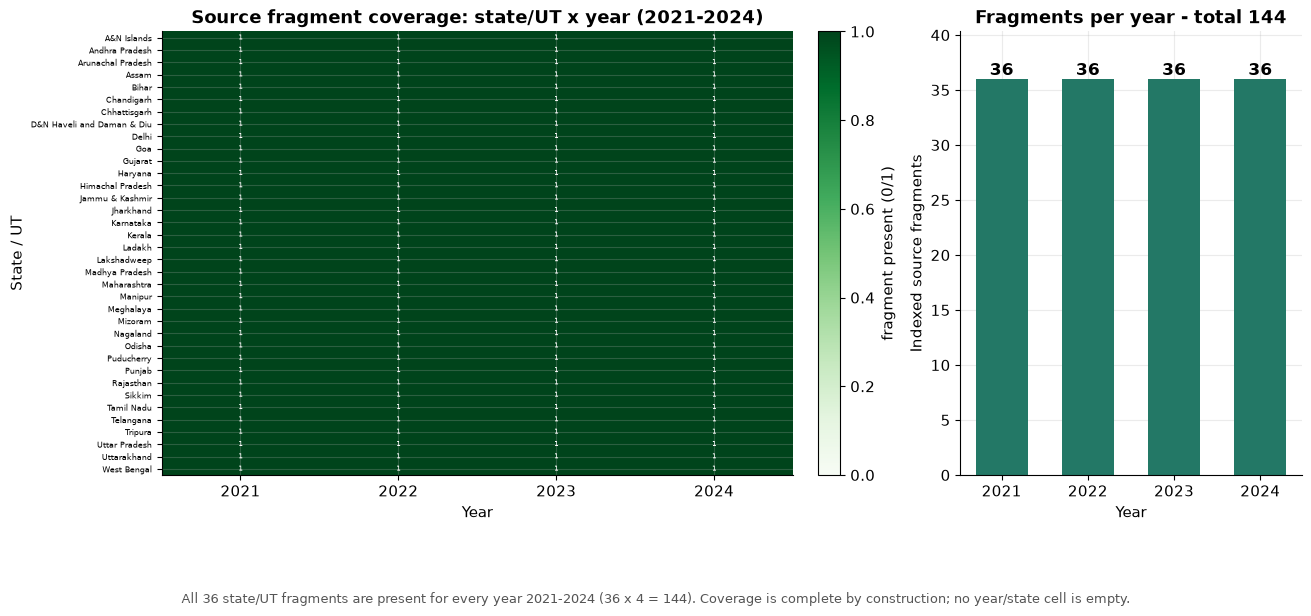

In [2]:

# Figure N01-01 · source_fragment_coverage
# State/UT x year coverage heatmap for the 144 manifest-selected fragments,
# plus fragments per year and the grand total.
cov = source_index.assign(n=1).pivot_table(
    index="state_ut", columns="year", values="n", aggfunc="sum", fill_value=0)
cov = cov.reindex(sorted(cov.index))
years = [int(c) for c in cov.columns]
n_states = len(cov)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2),
                         gridspec_kw={"width_ratios": [1.85, 1]},
                         constrained_layout=True)
im = axes[0].imshow(cov.values, aspect="auto", cmap="Greens", vmin=0, vmax=1)
axes[0].set_xticks(range(len(years)))
axes[0].set_xticklabels([str(y) for y in years])
axes[0].set_yticks(range(n_states))
axes[0].set_yticklabels(cov.index, fontsize=6)
axes[0].set_xlabel("Year")
axes[0].set_ylabel("State / UT")
axes[0].set_title("Source fragment coverage: state/UT x year (2021-2024)")
for i in range(n_states):
    for j in range(len(years)):
        axes[0].text(j, i, "1" if cov.values[i, j] else "0",
                     ha="center", va="center", fontsize=5,
                     color="white" if cov.values[i, j] else "#999")
fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04).set_label("fragment present (0/1)")

counts = source_index.groupby("year").size()
axes[1].bar([str(y) for y in counts.index], counts.values, color=PRIMARY, width=0.6)
for i, (y, c) in enumerate(counts.items()):
    axes[1].text(i, c, str(int(c)), ha="center", va="bottom", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Indexed source fragments")
axes[1].set_title(f"Fragments per year - total {int(len(source_index))}")
axes[1].set_ylim(0, counts.max() * 1.12)
fig_note(fig, "All 36 state/UT fragments are present for every year 2021-2024 (36 x 4 = 144). "
              "Coverage is complete by construction; no year/state cell is empty.")
plt.show()


## A real source fragment is wide

Andhra Pradesh’s 2021 fragment is identified by the source index and download manifest. One row represents a district; the crime categories are separate columns. The year and state association come from the selected manifest entry. Other state fragments can have generic `col_N` headings, so `source_inputs` supplies the corresponding year’s Andhra Pradesh `t1` header template.

In [3]:
ap_index_row = source_index.loc[(source_index["year"] == 2021) & (source_index["state_ut"] == "Andhra Pradesh")].iloc[0]
ap21 = next(x for x in source_inputs if x["year"] == 2021 and x["path"].relative_to(ROOT).as_posix() == ap_index_row["relative_path"])
with ap21["path"].open("r", encoding="utf-8-sig", newline="") as f:
    raw_reader = csv.DictReader(f)
    raw_rows = list(raw_reader)
raw_headers = ap21["header_template"]
district_rows = [r for r in raw_rows if r.get("State/UT/District") and not r["State/UT/District"].casefold().startswith("state:") and not r["State/UT/District"].isdigit() and classify_region(r["State/UT/District"]) == "administrative_district"]
murder_header = next(h for h in raw_headers[3:] if h.split(" | ")[-1].startswith("Murder ("))
rape_header = next(h for h in raw_headers[3:] if h.split(" | ")[-1].startswith("Rape ("))
official_header = next(h for h in raw_headers[3:] if h.split(" | ")[-1] == "Total Cognizable IPC crimes")
wide_preview = pd.DataFrame([
    {"District": r["State/UT/District"], "Murder (reported cases)": r[murder_header], "Rape (reported cases)": r[rape_header], "Official total (reported cases)": r[official_header]}
    for r in district_rows[:5]
])
print(f"Source: {ap21['path'].relative_to(ROOT)} | fragment: {ap21['table_id']} | state: {ap21['state_name']} | year: {ap21['year']}")
print(f"Header template: {Path(ap21['header_template_source']).name if Path(ap21['header_template_source']).is_absolute() else ap21['header_template_source']} | {len(raw_headers)} columns ({len(raw_headers)-3} category columns)")
print("Example source heading:", murder_header)
display(wide_preview)

Source: data\raw\2021\districtwise_ipc_bns_fragments\2021_andhra_pradesh_districtwise_ipc_crimes.csv | fragment: cii/2021/1_16730065601districtwiseipccrimes2021_t1 | state: Andhra Pradesh | year: 2021
Header template: data/raw/2021/districtwise_ipc_bns_fragments/2021_andhra_pradesh_districtwise_ipc_crimes.csv | 145 columns (142 category columns)
Example source heading: Offences affecting the Human Body | Murder (Sec.302 IPC)


,District,Murder (reported cases),Rape (reported cases),Official total (reported cases)
0,Anantapur,107,104,15017
1,Chittoor,68,13,12697
2,Cuddapah,64,28,8606
3,East Godavari,64,118,9535
4,Guntur,65,64,10587


## Trace one wide row into long observations

The active parser uses source row references such as `row_3` (CSV header is row 1 and the numbered heading row is row 2). Each present category cell becomes one observation. The same row/category/value is checked in both the canonical CSV selected by the serving manifest and the read-only SQLite release.

In [4]:
parsed_ap21 = parse_table(ap21["path"], ap21["year"], ap21["source_id"], geography_version=ap21["geography_version"], state_name_hint=ap21["state_name"], header_template=ap21["header_template"])
raw_trace = next(o for o in parsed_ap21 if o.region_name == "Anantapur" and o.original_category == "Murder")
assert raw_trace.reported_value == 107 and raw_trace.source_row_reference == "row_3"
trace_categories = {"Murder", "Rape", "Total Cognizable IPC crimes"}
long_example = pd.DataFrame([
    {"source row": o.source_row_reference, "state": o.state_name, "district": o.region_name, "year": o.year,
     "category": o.original_category, "reported count": o.reported_value, "quality": o.quality_status,
     "comparison": o.comparison_status, "geography ID": o.geography_id, "category ID": o.category_id}
    for o in parsed_ap21 if o.region_name == "Anantapur" and o.original_category in trace_categories
])
display(long_example)

canonical_row = next(row for row in csv.DictReader(canonical_path.open("r", encoding="utf-8-sig", newline=""))
                     if row["year"] == "2021" and row["state_name"] == "Andhra Pradesh" and row["region_name"] == "Anantapur" and row["original_category"] == "Murder")
sqlite_row = db.execute("""SELECT year,state_name,region_name,original_category,reported_value,source_id,source_row_reference,
    quality_status,comparison_status,geography_id,category_id FROM crime_observations
    WHERE year=2021 AND state_name='Andhra Pradesh' AND region_name='Anantapur' AND original_category='Murder'""").fetchone()
assert int(canonical_row["reported_value"]) == raw_trace.reported_value == sqlite_row[4] == 107
assert canonical_row["source_row_reference"] == raw_trace.source_row_reference == sqlite_row[6] == "row_3"
assert canonical_row["source_id"] == raw_trace.source_id == sqlite_row[5]
assert canonical_row["category_id"] == raw_trace.category_id == sqlite_row[10]
assert canonical_row["geography_id"] == raw_trace.geography_id == sqlite_row[9]
assert canonical_row["quality_status"] == sqlite_row[7] == "valid"
assert canonical_row["comparison_status"] == sqlite_row[8] == "eligible"
print("Raw parser, canonical CSV, and serving database agree: Anantapur / Murder / 2021 / 107 cases.")

ids = pd.DataFrame([
    {"identifier": "geography_id", "value": raw_trace.geography_id, "hash inputs": "geo | Andhra Pradesh | Anantapur | 2021"},
    {"identifier": "category_id", "value": raw_trace.category_id, "hash inputs": "cat | Murder"},
    {"identifier": "observation_id", "value": raw_trace.observation_id, "hash inputs": "obs | source ID | year | state | district | source header"},
])
display(ids)
assert raw_trace.geography_id == stable_id("geo", "Andhra Pradesh", "Anantapur", "2021")

,source row,state,district,year,category,reported count,quality,comparison,geography ID,category ID
0,row_3,Andhra Pradesh,Anantapur,2021,Murder,107,valid,eligible,65b0ad58134f6e65f7fa3db5,90d17a9d8cd3277ac20cf68d
1,row_3,Andhra Pradesh,Anantapur,2021,Rape,104,valid,eligible,65b0ad58134f6e65f7fa3db5,6bbcf2f20a57ed56515e954b
2,row_3,Andhra Pradesh,Anantapur,2021,Total Cognizable IPC crimes,15017,valid,eligible,65b0ad58134f6e65f7fa3db5,e70496b78818d5902eff0e9f


Raw parser, canonical CSV, and serving database agree: Anantapur / Murder / 2021 / 107 cases.


,identifier,value,hash inputs
0,geography_id,65b0ad58134f6e65f7fa3db5,geo | Andhra Pradesh | Anantapur | 2021
1,category_id,90d17a9d8cd3277ac20cf68d,cat | Murder
2,observation_id,8a6acb86cb20945c5aada891,obs | source ID | year | state | district | so...


## Raw-to-canonical example (illustrated)

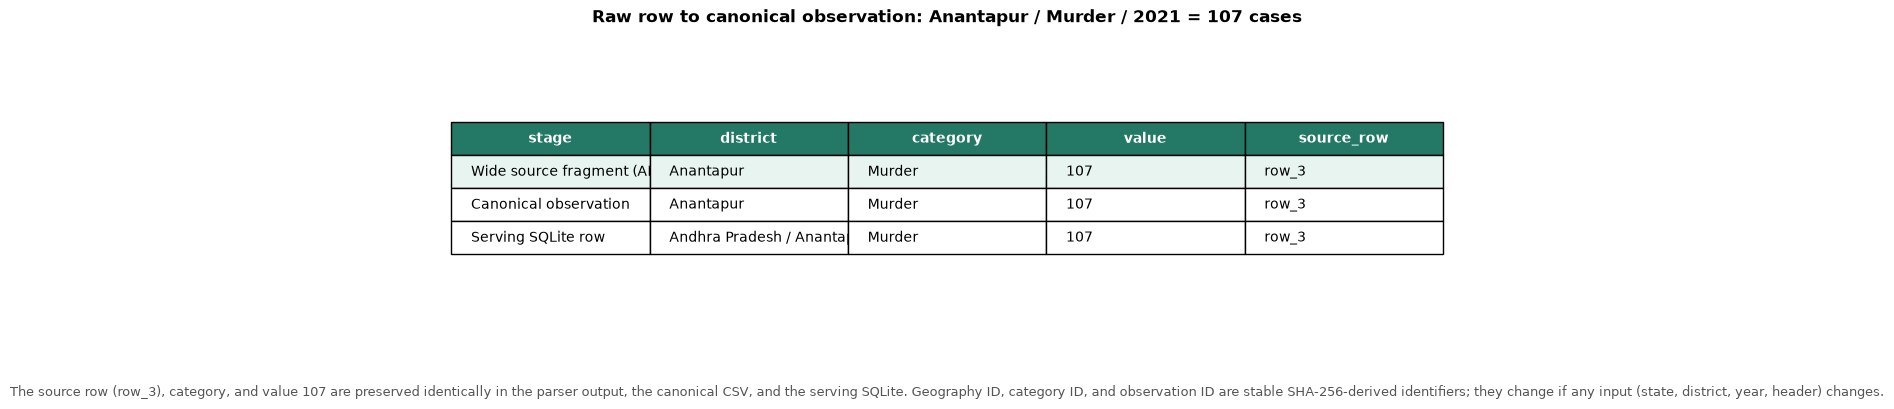

In [5]:

# Figure N01-05 · raw_to_canonical_example
# Rendered trace of the Anantapur Murder cell: source row -> canonical observation.
trace_rows = [
    {"stage": "Wide source fragment (AP 2021)", "district": "Anantapur", "category": "Murder",
     "value": int(raw_trace.reported_value), "source_row": raw_trace.source_row_reference},
    {"stage": "Canonical observation", "district": raw_trace.region_name, "category": raw_trace.original_category,
     "value": int(raw_trace.reported_value), "source_row": raw_trace.source_row_reference},
    {"stage": "Serving SQLite row", "district": "Andhra Pradesh / Anantapur", "category": "Murder",
     "value": int(sqlite_row[4]), "source_row": sqlite_row[6]},
]
trace_df = pd.DataFrame(trace_rows)

fig, ax = plt.subplots(figsize=(10, 3.4), constrained_layout=True)
ax.axis("off")
tbl = ax.table(cellText=trace_df.values, colLabels=trace_df.columns, loc="center", cellLoc="left")
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1, 1.7)
for (r, c), cell in tbl.get_celld().items():
    if r == 0:
        cell.set_text_props(weight="bold", color="white")
        cell.set_facecolor(PRIMARY)
    elif r == 1:
        cell.set_facecolor("#e7f4f0")
ax.set_title("Raw row to canonical observation: Anantapur / Murder / 2021 = 107 cases", fontsize=12, pad=10)
fig_note(fig, "The source row (row_3), category, and value 107 are preserved identically in the parser output, "
              "the canonical CSV, and the serving SQLite. Geography ID, category ID, and observation ID are stable "
              "SHA-256-derived identifiers; they change if any input (state, district, year, header) changes.")
plt.show()


Stable identifiers are the first 24 hexadecimal characters of SHA-256 over pipe-joined inputs. The geography hash includes the year, so a same-named unit in another year gets a different ID; this prevents treating a name match as stable boundaries. The observation ID also includes the source ID and original source header.

## Missing cells: real parser behavior, labeled fixture

This small fixture is **illustrative only** because the active canonical release has no null reported counts. It calls `parse_table`, the production parser, in a temporary directory. A written `0` stays zero; an existing blank or `NR` cell becomes a null observation with a reason; a column omitted at the end of a short row emits no observation at all.

In [6]:
from tempfile import TemporaryDirectory

with TemporaryDirectory(prefix="crimescope_parser_demo_") as temp_dir:
    fixture = Path(temp_dir) / "missing_cells_demo.csv"
    fixture.write_text(
        "section,sl_no,District,Murder,Existing blank,Not reported,Absent trailing\n"
        "State: Example State,1,Demo District,0,,NR\n",
        encoding="utf-8", newline=""
    )
    fixture_observations = parse_table(fixture, 2024, "illustrative-parser-fixture", state_name_hint="Example State")
fixture_table = pd.DataFrame([
    {"input cell": o.original_category, "reported_value": o.reported_value, "missing_reason": o.missing_reason,
     "quality_status": o.quality_status, "observation emitted": True}
    for o in fixture_observations
])
display(fixture_table)
assert len(fixture_observations) == 3
assert next(o for o in fixture_observations if o.original_category == "Murder").reported_value == 0
assert all(o.reported_value is None and o.missing_reason == "not_reported" for o in fixture_observations if o.original_category != "Murder")
assert not any(o.original_category == "Absent trailing" for o in fixture_observations)
print("The absent trailing column produced no row; no zero or null was fabricated for it.")

,input cell,reported_value,missing_reason,quality_status,observation emitted
0,Murder,0.0,NaN,valid,True
1,Existing blank,NaN,not_reported,warning,True
2,Not reported,NaN,not_reported,warning,True


The absent trailing column produced no row; no zero or null was fabricated for it.


## Reporting units, aggregates, and scope

The parser’s name rules classify `Total Districts` as `aggregate`. Such rows remain in the release for reconciliation, but are marked `aggregate_only` and are not included in eligible reporting-unit sums. The historical 2020 source was only a partial Andhra Pradesh slice, so the active source selector excludes that year rather than presenting it as national coverage.

In [7]:
row_accounting = db.execute("""SELECT count(*) AS canonical_rows,
    sum(CASE WHEN comparison_status='eligible' THEN 1 ELSE 0 END) AS eligible_rows,
    sum(CASE WHEN comparison_status='aggregate_only' THEN 1 ELSE 0 END) AS aggregate_rows,
    sum(CASE WHEN reported_value=0 THEN 1 ELSE 0 END) AS explicit_zeros,
    sum(CASE WHEN reported_value IS NULL THEN 1 ELSE 0 END) AS null_reported_counts
    FROM crime_observations""").fetchone()
accounting = pd.DataFrame([dict(zip(["canonical rows","eligible rows","aggregate rows","explicit zeros","null reported counts"], row_accounting))])
display(accounting)
assert tuple(row_accounting) == (567078, 546198, 20880, 329343, 0)
assert release["rows"] == row_accounting[0]
assert release["valid_observations"] == row_accounting[1]

aggregate_example = db.execute("""SELECT year,state_name,original_region_name,original_category,reported_value,
    quality_status,comparison_status,quarantine_reason FROM crime_observations
    WHERE comparison_status='aggregate_only' LIMIT 1""").fetchone()
display(pd.DataFrame([dict(zip(["year","state","source aggregate label","category","reported count","quality","comparison","reason"], aggregate_example))]))
print("Parser classification example:", classify_region("Total Districts"))

,canonical rows,eligible rows,aggregate rows,explicit zeros,null reported counts
0,567078,546198,20880,329343,0


,year,state,source aggregate label,category,reported count,quality,comparison,reason
0,2021,Andhra Pradesh,Total Districts,Murder,956,valid,aggregate_only,aggregate_row_excluded_from_comparison


Parser classification example: aggregate


## Canonical observations: accounting and value breakdown

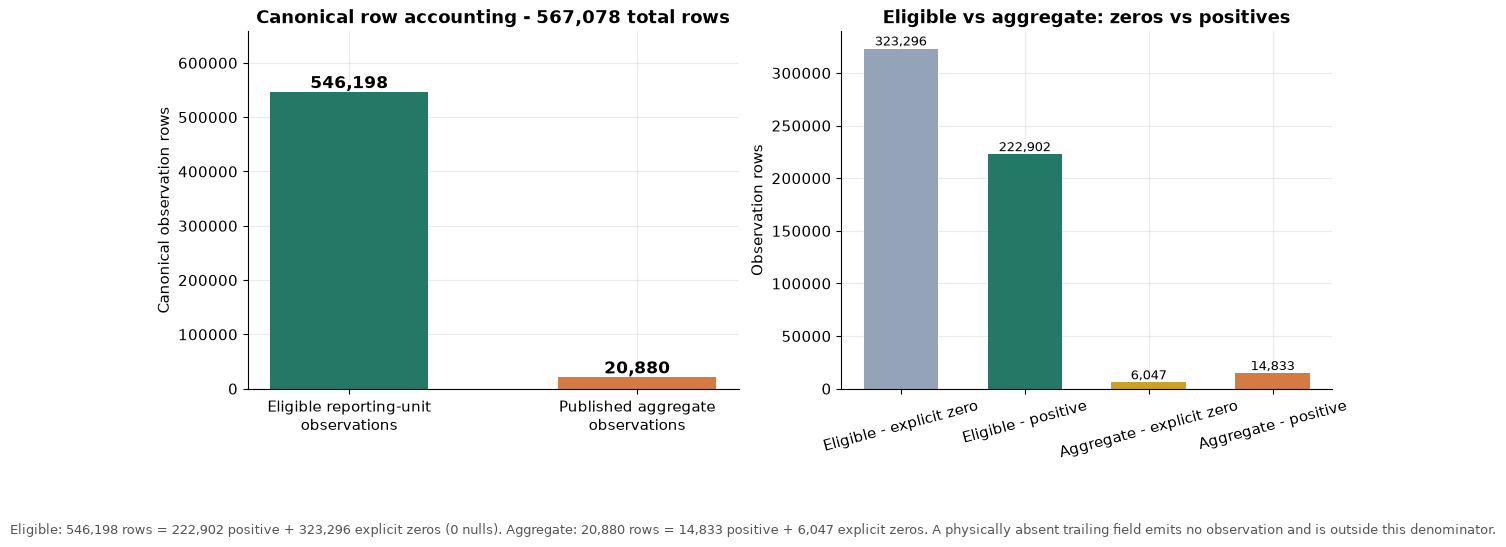

In [8]:

# Figure N01-02 · canonical_row_accounting
# Eligible reporting-unit observations vs published aggregates (observation rows, not case counts).
row_accounting = db.execute("""SELECT count(*) AS canonical_rows,
    sum(CASE WHEN comparison_status='eligible' THEN 1 ELSE 0 END) AS eligible_rows,
    sum(CASE WHEN comparison_status='aggregate_only' THEN 1 ELSE 0 END) AS aggregate_rows
    FROM crime_observations""").fetchone()
canonical, eligible, aggregate = row_accounting

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
bars = axes[0].bar(["Eligible reporting-unit\nobservations", "Published aggregate\nobservations"],
                   [eligible, aggregate], color=[PRIMARY, ACCENT], width=0.55)
for rect, v in zip(bars, [eligible, aggregate]):
    axes[0].text(rect.get_x() + rect.get_width() / 2, v, f"{v:,}", ha="center", va="bottom",
                 fontsize=12, fontweight="bold")
axes[0].set_ylabel("Canonical observation rows")
axes[0].set_ylim(0, canonical * 1.16)
axes[0].set_title(f"Canonical row accounting - {canonical:,} total rows")

# Composition of eligible rows: explicit zeros vs positives
eligible_zeros = db.execute("""SELECT sum(CASE WHEN comparison_status='eligible' AND reported_value=0 THEN 1 ELSE 0 END),
    sum(CASE WHEN comparison_status='eligible' AND reported_value>0 THEN 1 ELSE 0 END),
    sum(CASE WHEN comparison_status='eligible' AND reported_value IS NULL THEN 1 ELSE 0 END)
    FROM crime_observations""").fetchone()
ez, ep, en = eligible_zeros
agg_zeros = db.execute("""SELECT sum(CASE WHEN comparison_status='aggregate_only' AND reported_value=0 THEN 1 ELSE 0 END),
    sum(CASE WHEN comparison_status='aggregate_only' AND reported_value>0 THEN 1 ELSE 0 END)
    FROM crime_observations""").fetchone()
az, ap = agg_zeros

labels = ["Eligible - explicit zero", "Eligible - positive", "Aggregate - explicit zero", "Aggregate - positive"]
values = [ez, ep, az, ap]
colors = [GREY, PRIMARY, "#c9a227", ACCENT]
bars = axes[1].bar(labels, values, color=colors, width=0.6)
for rect, v in zip(bars, values):
    axes[1].text(rect.get_x() + rect.get_width() / 2, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
axes[1].set_ylabel("Observation rows")
axes[1].set_title("Eligible vs aggregate: zeros vs positives")
axes[1].tick_params(axis="x", rotation=15)
fig_note(fig, f"Eligible: {eligible:,} rows = {ep:,} positive + {ez:,} explicit zeros (0 nulls). "
              f"Aggregate: {aggregate:,} rows = {ap:,} positive + {az:,} explicit zeros. "
              "A physically absent trailing field emits no observation and is outside this denominator.")
plt.show()


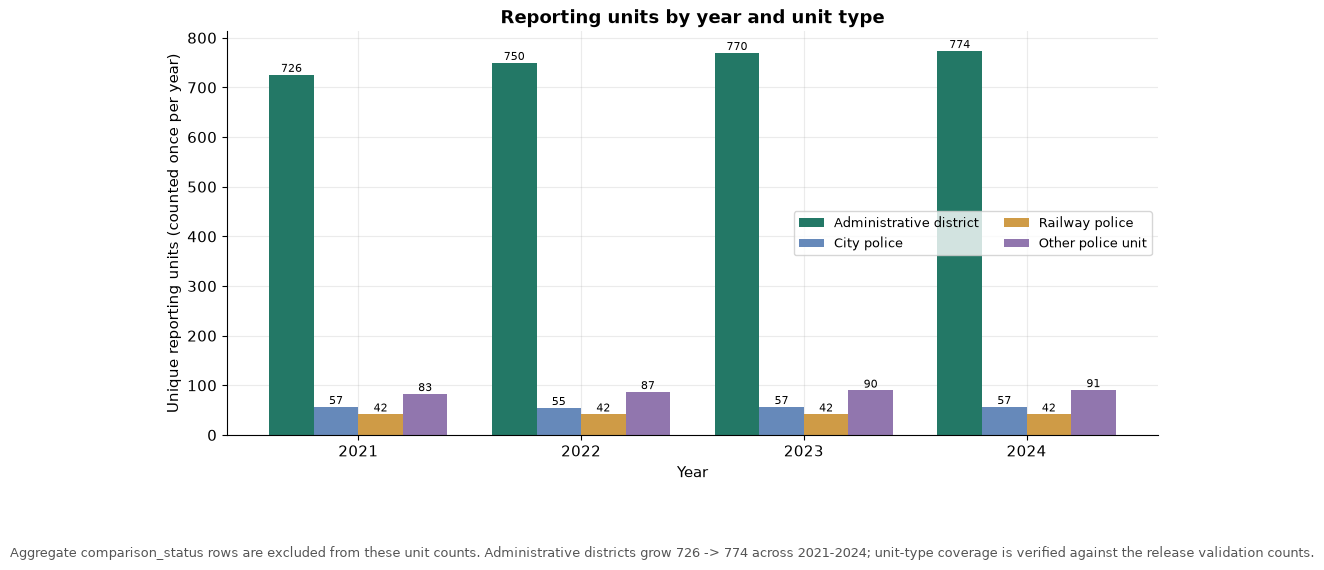

In [9]:

# Figure N01-04 · reporting_unit_types_by_year
# Unique reporting units counted once per year, by unit type. Aggregates kept out of the bars.
region_counts = release.get("validation", {}).get("region_counts_by_year_type", [])
rc = pd.DataFrame(region_counts, columns=["year", "unit_type", "units"])
types_order = ["administrative_district", "city_police", "railway", "other_police_unit"]
rc = rc[rc["unit_type"].isin(types_order)]
pivot = rc.pivot(index="unit_type", columns="year", values="units").reindex(types_order)

fig, ax = plt.subplots(figsize=(10, 4.8), constrained_layout=True)
years = sorted(pivot.columns.astype(int))
x = np.arange(len(years))
width = 0.2
type_labels = {"administrative_district": "Administrative district",
               "city_police": "City police",
               "railway": "Railway police",
               "other_police_unit": "Other police unit"}
for i, t in enumerate(types_order):
    vals = [int(pivot.loc[t, y]) for y in years]
    ax.bar(x + (i - 1.5) * width, vals, width, label=type_labels[t], color=SERIES[i])
    for xi, v in zip(x + (i - 1.5) * width, vals):
        ax.text(xi, v, str(v), ha="center", va="bottom", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels([str(y) for y in years])
ax.set_xlabel("Year")
ax.set_ylabel("Unique reporting units (counted once per year)")
ax.set_title("Reporting units by year and unit type")
ax.legend(fontsize=9, ncol=2)
fig_note(fig, "Aggregate comparison_status rows are excluded from these unit counts. "
              "Administrative districts grow 726 -> 774 across 2021-2024; unit-type coverage is verified "
              "against the release validation counts.")
plt.show()


### Interpretation and limitations

The active release contains 2021–2024 only. It has 567,078 canonical observations: 546,198 eligible reporting-unit observations and 20,880 aggregate observations. All 329,343 explicit zero cells remain zero; there are no null reported counts in this release. For context, the documented 2020 partial Andhra Pradesh slice was 2,944 rows (2,802 eligible and 142 aggregate) and is excluded because it does not represent national coverage.

Three cases are different: **2020 is excluded as an out-of-scope partial year; an absent trailing cell is skipped with no observation created; an aggregate row is retained for reconciliation but excluded from reporting-unit comparisons.** Existing blank/NR cells would remain null with a missing reason; none occur in the active release. Zero nulls do not prove every source table is complete.

## Appendix: additional preprocessing diagnostics

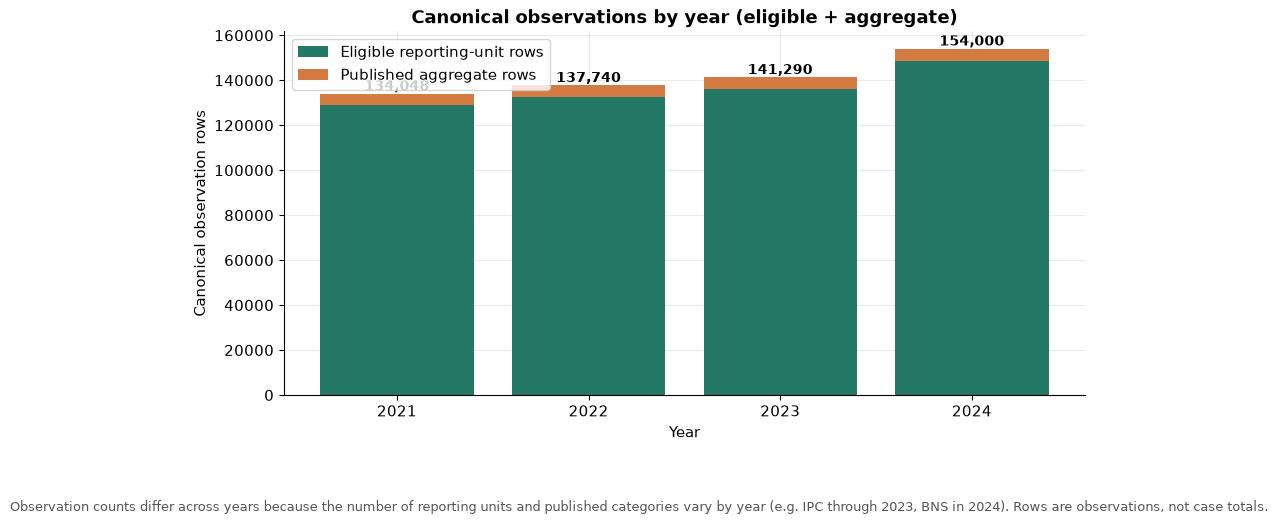

In [10]:

# Figure N01-06 · canonical_observations_by_year (optional)
# Stacked eligible + aggregate observation rows by year.
year_rows = []
for y in (2021, 2022, 2023, 2024):
    el = db.execute("""SELECT count(*) FROM crime_observations WHERE year=? AND comparison_status='eligible'""", (y,)).fetchone()[0]
    ag = db.execute("""SELECT count(*) FROM crime_observations WHERE year=? AND comparison_status='aggregate_only'""", (y,)).fetchone()[0]
    year_rows.append({"year": y, "eligible": el, "aggregate": ag})
yr = pd.DataFrame(year_rows)

fig, ax = plt.subplots(figsize=(9, 4.4), constrained_layout=True)
ax.bar(yr["year"].astype(str), yr["eligible"], label="Eligible reporting-unit rows", color=PRIMARY)
ax.bar(yr["year"].astype(str), yr["aggregate"], bottom=yr["eligible"], label="Published aggregate rows", color=ACCENT)
for _, r in yr.iterrows():
    ax.text(str(r["year"]), r["eligible"] + r["aggregate"], f"{int(r['eligible']+r['aggregate']):,}",
            ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("Canonical observation rows")
ax.set_title("Canonical observations by year (eligible + aggregate)")
ax.legend()
fig_note(fig, "Observation counts differ across years because the number of reporting units and published "
              "categories vary by year (e.g. IPC through 2023, BNS in 2024). Rows are observations, not case totals.")
plt.show()


C:\Users\saikiran\AppData\Local\Temp\ipykernel_10180\1300551239.py:3: DtypeWarning: Columns (0: mapped_geography_id) have mixed types. Specify dtype option on import or set low_memory=False.
  feat24 = pd.read_csv(release["source_dataset"]["path"])


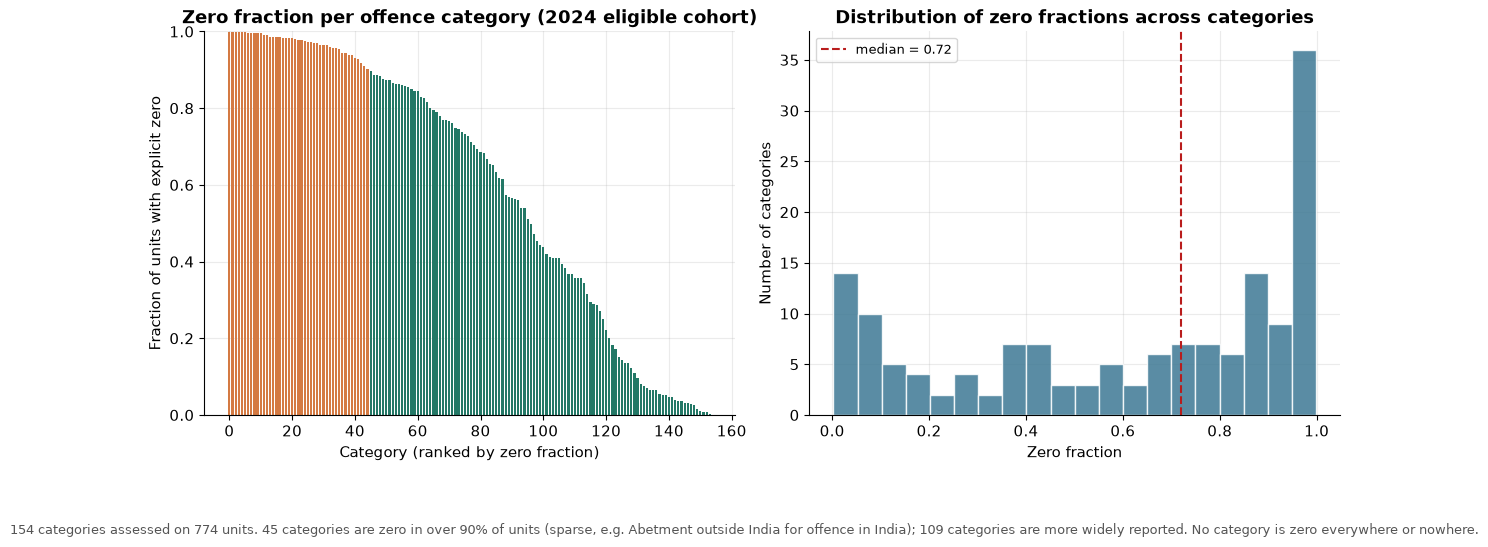

In [11]:

# Figure N01-07 · zero_fraction_by_category (optional)
# Fraction of reporting units with an explicit zero per category, 2024 eligible cohort.
feat24 = pd.read_csv(release["source_dataset"]["path"])
feat24 = feat24[(feat24["year"] == 2024) & (feat24["region_type"] == "administrative_district")
                & (feat24["comparison_status"] == "eligible")]
zf = feat24.groupby("original_category")["reported_value"].apply(lambda s: (s == 0).mean()).sort_values(ascending=False)
n_cat = len(zf)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
axes[0].bar(range(n_cat), zf.values, color=np.where(zf.values > 0.9, ACCENT, PRIMARY), width=0.7)
axes[0].set_xlabel("Category (ranked by zero fraction)")
axes[0].set_ylabel("Fraction of units with explicit zero")
axes[0].set_title("Zero fraction per offence category (2024 eligible cohort)")
axes[0].set_ylim(0, 1)
sparse = zf[zf > 0.9]
dense = zf[zf <= 0.9]
axes[1].hist(zf.values, bins=20, color=BLUE, alpha=0.85, edgecolor="white")
axes[1].axvline(zf.median(), color=RED, ls="--", lw=1.5,
                label=f"median = {zf.median():.2f}")
axes[1].set_xlabel("Zero fraction")
axes[1].set_ylabel("Number of categories")
axes[1].set_title("Distribution of zero fractions across categories")
axes[1].legend(fontsize=9)
fig_note(fig, f"{n_cat} categories assessed on {feat24['geography_id'].nunique()} units. "
              f"{len(sparse)} categories are zero in over 90% of units (sparse, e.g. {sparse.index[0] if len(sparse) else ''}); "
              f"{len(dense)} categories are more widely reported. No category is zero everywhere or nowhere.")
plt.show()


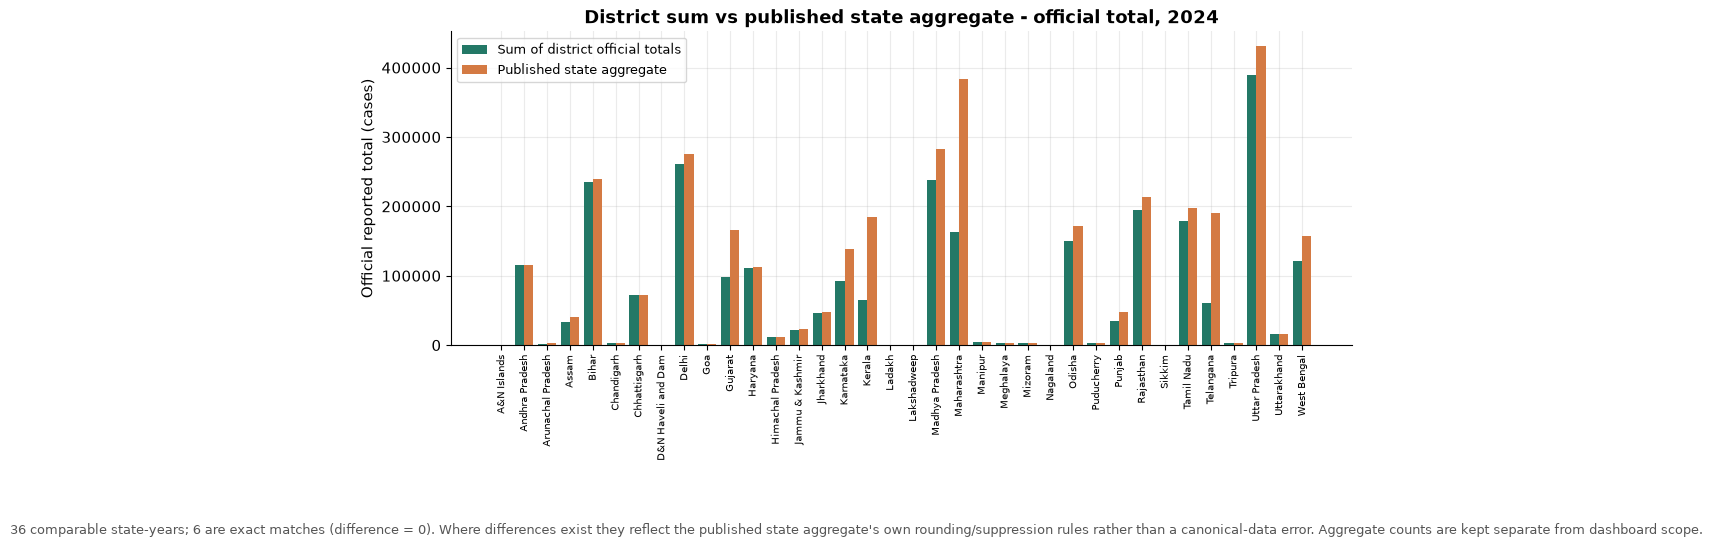

In [12]:

# Figure N01-08 · published_total_reconciliation (optional)
# Sum of district official totals vs state-level published aggregate for the official-total category, 2024.
ot_cat = db.execute("""SELECT category_id FROM crime_observations
    WHERE year=2024 AND original_category='Total Cognizable IPC/BNS crimes' LIMIT 1""").fetchone()
if ot_cat is None:
    print("Skipping reconciliation: official-total category not found.")
else:
    ot_id = ot_cat[0]
    state_sum = db.execute("""SELECT state_name, sum(reported_value) AS district_sum
        FROM crime_observations WHERE year=2024 AND region_type='administrative_district'
          AND comparison_status='eligible' AND category_id=? GROUP BY state_name""", (ot_id,)).fetchall()
    state_agg = db.execute("""SELECT state_name, reported_value AS state_total
        FROM crime_observations WHERE year=2024 AND comparison_status='aggregate_only'
          AND original_region_name='Total Districts' AND category_id=?""", (ot_id,)).fetchall()
    sum_map = {s: v for s, v in state_sum}
    agg_map = {s: v for s, v in state_agg}
    states = sorted(set(sum_map) & set(agg_map))
    diffs = [(s, sum_map[s], agg_map[s], sum_map[s] - agg_map[s]) for s in states]
    rec = pd.DataFrame(diffs, columns=["state", "district_sum", "state_aggregate", "difference"])
    exact = int((rec["difference"] == 0).sum())

    fig, ax = plt.subplots(figsize=(10, 4.6), constrained_layout=True)
    if len(rec):
        x = np.arange(len(rec))
        ax.bar(x - 0.2, rec["district_sum"], width=0.4, label="Sum of district official totals", color=PRIMARY)
        ax.bar(x + 0.2, rec["state_aggregate"], width=0.4, label="Published state aggregate", color=ACCENT)
        ax.set_xticks(x)
        ax.set_xticklabels([s[:18] for s in rec["state"]], rotation=90, fontsize=7)
        ax.set_ylabel("Official reported total (cases)")
        ax.set_title("District sum vs published state aggregate - official total, 2024")
        ax.legend(fontsize=9)
    fig_note(fig, f"{len(rec)} comparable state-years; {exact} are exact matches (difference = 0). "
                  "Where differences exist they reflect the published state aggregate's own rounding/suppression "
                  "rules rather than a canonical-data error. Aggregate counts are kept separate from dashboard scope.")
    plt.show()


### Partial 2020 scope

In [13]:

# Figure N01-09 · partial_2020_scope (optional) - not drawn
# The 2020 Andhra Pradesh slice is excluded from the active release; no national-comparison figure is drawn.
print("2020 partial Andhra Pradesh input is excluded from the active release (2021-2024 only). "
      "It is a historical partial slice and is outside the national comparison, so no coverage figure is drawn for it.")


2020 partial Andhra Pradesh input is excluded from the active release (2021-2024 only). It is a historical partial slice and is outside the national comparison, so no coverage figure is drawn for it.
